# COM7022 Machine Learning Portfolio: code

Student ID: 25138486

The sections of this notebook follow the sections of the report in the same order, and each figure in Task 1 is a screenshot of the cell under the same section number. Run the notebook from top to bottom with **Sales-[5444].csv** in the same folder.

## Setup

In [1]:
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score)

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', None)
SEED = 42

# Task 1
## 2. Data
### 2.1 Structure (Figure 1)

In [2]:
df = pd.read_csv('Sales-[5444].csv', encoding='utf-8-sig')
raw = df.copy()   # untouched copy, kept for before-and-after comparisons
print('Shape:', df.shape)
df.head(3)

Shape: (1000, 10)


,Item_Name,details,Catatory,price,priceWithCurrency,available,text,sold,lastUpdated,itemLocation
0,Dior,Christian Dior Sauvage Men's EDP 3.4 oz Fragra...,Eau de Parfum,84.99,US $84.99/ea,10.0,More than 10 available / 116 sold,NaN,"May 24, 2024 10:03:04 PDT","Allen Park, Michigan, United States"
1,AS SHOW,A-v-entus Eau de Parfum 3.3 oz 100ML Millesime...,Eau de Parfum,NaN,US $109.99,8.0,8 available / 48 sold,48.0,"May 23, 2024 23:07:49 PDT","Atlanta, Georgia, Canada"
2,Unbranded,HOGO BOSS cologne For Men 3.4 oz,Eau de Toilette,100.00,US $100.00,10.0,More than 10 available / 27 sold,27.0,"May 22, 2024 21:55:43 PDT","Dearborn, Michigan, United States"


### 2.2 Data types (Figure 2)

In [3]:
print(df.dtypes)

Item_Name                str
details                  str
Catatory                 str
price                float64
priceWithCurrency        str
available            float64
text                     str
sold                 float64
lastUpdated              str
itemLocation             str
dtype: object


### 2.3 Missing values (Figure 3)

In [4]:
missing = df.isna().sum()
print(missing)
print('Total missing cells:', missing.sum(), f'({missing.sum() / df.size:.2%})')
print('Rows with at least one missing value:', df.isna().any(axis=1).sum())

Item_Name              1
details                0
Catatory               3
price                  5
priceWithCurrency      1
available            111
text                   3
sold                   8
lastUpdated           53
itemLocation           0
dtype: int64
Total missing cells: 185 (1.85%)
Rows with at least one missing value: 163


### 2.4 Descriptive statistics (Figure 4)

In [5]:
print(df.describe().round(2))

sold = df['sold'].dropna()
top10 = sold.sort_values(ascending=False).head(len(sold) // 10)
print('\nMedian units sold:', sold.median(), '| mean units sold:', round(sold.mean()))
print(f'Share of all units sold by the top 10% of listings: {top10.sum() / sold.sum():.0%}')

        price  available      sold
count  995.00     889.00    992.00
mean    46.43      20.05    775.25
std     35.55      61.55   3211.43
min      3.00       2.00      1.00
25%     22.99       5.00     14.00
50%     35.71      10.00     49.50
75%     59.00      10.00    324.75
max    259.09     842.00  54052.00

Median units sold: 49.5 | mean units sold: 775
Share of all units sold by the top 10% of listings: 82%


## 3. Methods
### 3.1 Data preparation
#### 3.1.1 Column names and text gaps (Figure 5)

In [6]:
df.columns = df.columns.str.lower()
df = df.rename(columns={'catatory': 'category'})
print(list(df.columns))

text_cols = ['item_name', 'category', 'text', 'pricewithcurrency']
print('Missing text values before:', df[text_cols].isna().sum().sum())
df[text_cols] = df[text_cols].fillna('Unknown')
print('Missing text values after: ', df[text_cols].isna().sum().sum())

['item_name', 'details', 'category', 'price', 'pricewithcurrency', 'available', 'text', 'sold', 'lastupdated', 'itemlocation']
Missing text values before: 8
Missing text values after:  0


#### 3.1.2 Approach to missing numbers (Figure 6)

In [7]:
# Do listings with a missing value sell differently? If so, deleting them would bias the results.
print('Median units sold, by whether the date is missing:')
print(raw.groupby(raw['lastUpdated'].isna())['sold'].median())

# The numeric columns are skewed, so the median is a fairer fill value than the mean.
print(raw[['price', 'sold', 'available']].agg(['skew', 'median', 'mean']).round(2))

Median units sold, by whether the date is missing:
lastUpdated
False    59.0
True      5.0
Name: sold, dtype: float64
        price    sold  available
skew     2.04    9.71       8.16
median  35.71   49.50      10.00
mean    46.43  775.25      20.05


#### 3.1.3 Price and units sold (Figure 7)

In [8]:
# Recover missing values from the text columns, then fill any gaps left with the median
price_text = df['pricewithcurrency'].str.replace(',', '').str.extract(r'(\d+\.?\d*)')[0]
sold_text = df['text'].str.replace(',', '').str.extract(r'(\d+)\s+sold', flags=re.IGNORECASE)[0]

for col, from_text in [('price', price_text.astype(float)), ('sold', sold_text.astype(float))]:
    both = df[col].notna() & from_text.notna()
    match = (from_text[both] == df.loc[both, col]).mean()
    print(f'{col}: the text matches the stored value for {match:.1%} of listings')
    missing_before = df[col].isna().sum()
    df[col] = df[col].fillna(from_text)
    recovered = missing_before - df[col].isna().sum()
    df[col] = df[col].fillna(df[col].median())
    print(f'   missing: {missing_before} | recovered from the text: {recovered}',
          f'| filled with the median: {missing_before - recovered}')

price: the text matches the stored value for 100.0% of listings
   missing: 5 | recovered from the text: 5 | filled with the median: 0
sold: the text matches the stored value for 99.9% of listings
   missing: 8 | recovered from the text: 2 | filled with the median: 6


#### 3.1.4 Update date (Figure 8)

In [9]:
# remove the time zone (e.g. 'PDT'), then convert the text to a date
date_text = df['lastupdated'].str.replace(r'\s+[A-Za-z]{2,4}$', '', regex=True)
df['lastupdated_dt'] = pd.to_datetime(date_text, format='%b %d, %Y %H:%M:%S', errors='coerce')
failed = df['lastupdated'].notna() & df['lastupdated_dt'].isna()
print('Missing dates:', df['lastupdated_dt'].isna().sum())
print('Text that failed to convert:', failed.sum())

df['lastupdated_dt'] = df['lastupdated_dt'].fillna(df['lastupdated_dt'].median())
ref_date = df['lastupdated_dt'].max() + pd.Timedelta(days=1)
df['days_since_update'] = (ref_date - df['lastupdated_dt']).dt.days
df = df.drop(columns=['lastupdated'])     # the text version is no longer needed
print('Reference date:', ref_date.date())
print(df['days_since_update'].describe().round(1))

Missing dates: 53
Text that failed to convert: 0
Reference date: 2024-05-25
count    1000.0
mean        8.7
std        31.2
min         1.0
25%         1.0
50%         2.0
75%         6.0
max       582.0
Name: days_since_update, dtype: float64


#### 3.1.5 Stock (Figures 9 and 10)

In [10]:
# What does the text say about stock, and which of these listings have no stock number?
t = df['text']
conditions = [t.str.contains('More than 10 available', case=False),
              t.str.contains('Last One', case=False),
              t.str.contains('Limited quantity', case=False),
              t.str.contains(r'^\s*[\d,]+ available', regex=True)]
labels = ['More than 10 available', 'Last One', 'Limited quantity', 'Exact number']
status = pd.Series(np.select(conditions, labels, default='Other or no text'), index=df.index)
print(pd.crosstab(status.rename('stock status'), df['available'].isna().rename('stock missing'),
                  margins=True))
more_than_10 = status == 'More than 10 available'
print('\nValue stored for "More than 10 available":', df.loc[more_than_10, 'available'].unique())

stock missing           False  True   All
stock status                             
Exact number              592     0   592
Last One                    0    47    47
Limited quantity            0    59    59
More than 10 available    297     0   297
Other or no text            0     5     5
All                       889   111  1000

Value stored for "More than 10 available": [10.]


In [11]:
df['available_10plus'] = more_than_10.astype(int)     # true stock is only known to be at least 10
df['available_limited'] = (status == 'Limited quantity').astype(int)

last_one = df['available'].isna() & (status == 'Last One')
df.loc[last_one, 'available'] = 1
stock_imputed = df['available'].isna()        # remembered for the stock sensitivity test
print('"Last One" set to 1:', last_one.sum())
print('Filled with the median of', df['available'].median(), ':', stock_imputed.sum())
df['available'] = df['available'].fillna(df['available'].median())

print('\nMedian price and units sold, by "Limited quantity":')
print(df.groupby('available_limited')[['price', 'sold']].median())

"Last One" set to 1: 47
Filled with the median of 9.0 : 64

Median price and units sold, by "Limited quantity":
                   price    sold
available_limited               
0                  34.99    42.0
1                  46.33  1511.0


#### 3.1.6 Product category (Figure 11)

In [12]:
print('Distinct labels:', df['category'].nunique(),
      '| labels used by fewer than five listings:', (df['category'].value_counts() < 5).sum())

c = df['category'].str.lower().str.replace('~', ' ')
c = c.str.replace(r'\s+', ' ', regex=True).str.strip()
has = lambda pattern: c.str.contains(pattern, regex=True)
rules = [   # checked in order: the first rule that matches decides the product type
    # mixed types, e.g. 'eau de toilette & parfum'
    ('other', (has('toil') & has('parf')) | (has('toil') & has('cologne'))
              | (has('parf') & has('cologne'))),
    # not a single fragrance: gift sets, deodorants, oils
    ('other', has(r'deodorant|\boil\b|roll on|freshener|body spray|splash|gift|\bset')),
    ('eau_de_toilette', has(r'toil|\bedt\b')),
    ('eau_de_parfum', has(r'eau de parf|eau de perf|\bedp\b')),
    ('eau_de_cologne', has(r'cologne|\bedc\b')),
    ('parfum', has(r'parfum|elixir|extrait')),
    ('perfume_generic', has(r'perfume|fragrance')),
]
df['category_grouped'] = np.select([m for _, m in rules], [name for name, _ in rules], default='other')
print(df['category_grouped'].value_counts())

Distinct labels: 64 | labels used by fewer than five listings: 53
category_grouped
eau_de_toilette    460
eau_de_parfum      314
perfume_generic     85
eau_de_cologne      70
other               42
parfum              29
Name: count, dtype: int64


#### 3.1.7 Outliers (Figures 12 and 13)

In [13]:
num = ['price', 'sold', 'available', 'days_since_update']
q1, q3 = df[num].quantile(0.25), df[num].quantile(0.75)
iqr = q3 - q1
print('Values outside 1.5 x IQR:')
print(((df[num] < q1 - 1.5 * iqr) | (df[num] > q3 + 1.5 * iqr)).sum())

print('\nLargest units sold, checked against the text:')
largest = df.nlargest(3, 'sold')[['details', 'sold', 'text']]
print(largest.assign(details=largest['details'].str[:30]).to_string())

Values outside 1.5 x IQR:
price                 54
sold                 138
available             98
days_since_update    135
dtype: int64

Largest units sold, checked against the text:
                            details     sold                                      text
81   Ck One by Calvin Klein Cologne  54052.0  Limited quantity available / 54,052 sold
642  Cool Water by Davidoff 4.2 oz   40130.0  Limited quantity available / 40,130 sold
184  Versace Eros by Gianni Versace  31718.0  Limited quantity available / 31,718 sold


In [14]:
# Check every exact stock number in the text against the stored value
exact = df['text'].str.extract(r'^\s*([\d,]+) available')[0].str.replace(',', '').astype(float)
wrong = exact.notna() & (exact != df['available'])
print(df.loc[wrong, ['available', 'text']])
df.loc[wrong, 'available'] = exact[wrong]          # restore the lost thousands digit
print('Corrected:', wrong.sum())

print('\nMissing values left in the numeric features:', df[num].isna().sum().sum())
print(df[num].describe().round(2))

    available                          text
47      756.0  1,756 available / 5,023 sold
74      322.0    1,322 available / 417 sold
77      323.0  1,323 available / 4,972 sold
Corrected: 3

Missing values left in the numeric features: 0


         price      sold  available  days_since_update
count  1000.00   1000.00    1000.00            1000.00
mean     46.48    769.62      21.44               8.74
std      35.53   3199.17      95.28              31.22
min       3.00      1.00       1.00               1.00
25%      22.99     14.00       4.00               1.00
50%      35.71     50.00       9.00               2.00
75%      59.00    317.50      10.00               6.00
max     259.09  54052.00    1756.00             582.00


### 3.2 Feature selection (Figure 14)

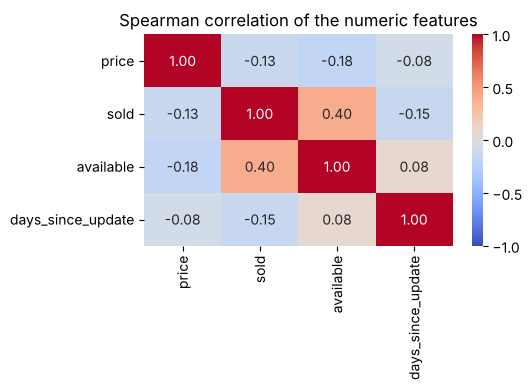

In [15]:
corr = df[num].corr(method='spearman')
plt.figure(figsize=(5.5, 4))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Spearman correlation of the numeric features')
plt.tight_layout(); plt.show()

### 3.3 Transformation
#### 3.3.1 Log transformation (Figure 15)

                   skew before  skew after
price                     2.04        0.11
sold                      9.75        0.54
available                12.58        1.75
days_since_update        13.32        1.55


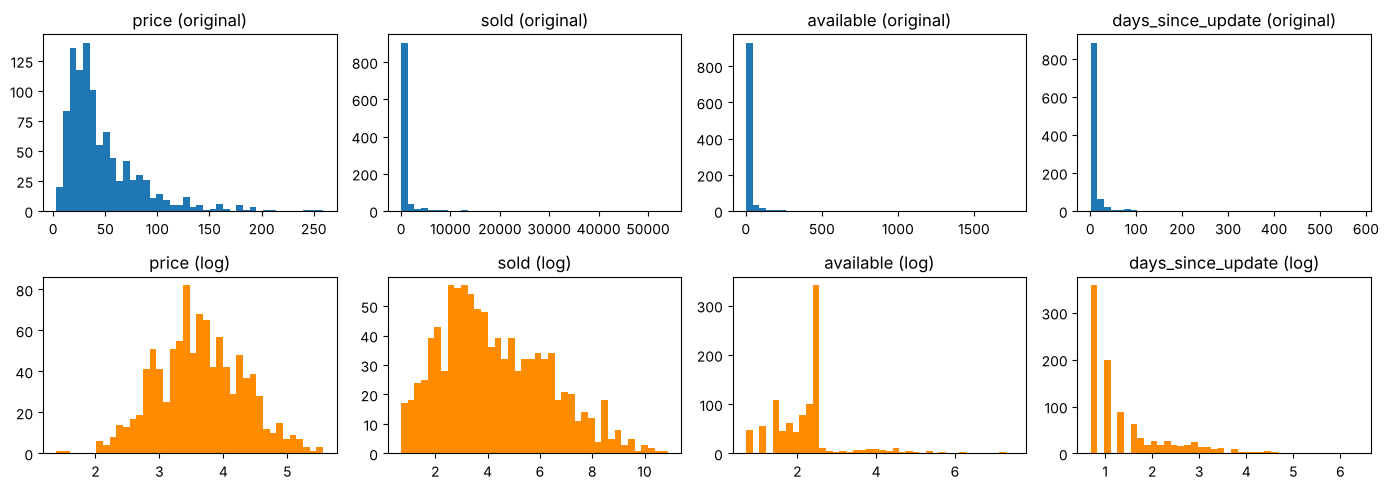

In [16]:
df_log = np.log1p(df[num])          # log(1 + x), so zero stays defined
print(pd.DataFrame({'skew before': df[num].skew(), 'skew after': df_log.skew()}).round(2))

fig, axes = plt.subplots(2, 4, figsize=(14, 5))
for i, col in enumerate(num):
    axes[0, i].hist(df[col], bins=40); axes[0, i].set_title(f'{col} (original)')
    axes[1, i].hist(df_log[col], bins=40, color='darkorange'); axes[1, i].set_title(f'{col} (log)')
plt.tight_layout(); plt.show()

#### 3.3.2 Scaling (Figure 16)

In [17]:
scaled = pd.DataFrame(StandardScaler().fit_transform(df_log), columns=num)
summary = pd.DataFrame({'sd before': df_log.std(),
                        'mean after': scaled.mean(), 'sd after': scaled.std()})
print(summary.round(2) + 0.0)       # + 0.0 avoids printing -0.0

                   sd before  mean after  sd after
price                   0.67         0.0       1.0
sold                    2.06         0.0       1.0
available               0.93         0.0       1.0
days_since_update       0.97         0.0       1.0


#### 3.3.3 Encoding product type (Figure 17)

In [18]:
cat_dummies = pd.get_dummies(df['category_grouped'], prefix='cat', dtype=int)
X = pd.concat([scaled, cat_dummies], axis=1)      # the final feature table
print('Feature table:', X.shape)
print(X.head(3).round(2).to_string())

Feature table: (1000, 10)
   price  sold  available  days_since_update  cat_eau_de_cologne  cat_eau_de_parfum  cat_eau_de_toilette  cat_other  cat_parfum  cat_perfume_generic
0   1.22  0.23       0.19              -0.83                   0                  1                    0          0           0                    0
1   1.60 -0.20      -0.02              -0.83                   0                  1                    0          0           0                    0
2   1.46 -0.47       0.19              -0.41                   0                  0                    1          0           0                    0


### 3.4 Dimensionality reduction (PCA) (Figures 18 and 19)

In [19]:
pca = PCA().fit(X)
ratio = pca.explained_variance_ratio_
print(pd.DataFrame({'variance': ratio, 'cumulative': ratio.cumsum()},
                   index=[f'PC{i + 1}' for i in range(len(ratio))]).round(3).head(5))
print('\nLoadings of the first four components:')
loadings = pd.DataFrame(pca.components_[:4].T, index=X.columns, columns=['PC1', 'PC2', 'PC3', 'PC4'])
print(loadings.round(2))

     variance  cumulative
PC1     0.337       0.337
PC2     0.234       0.571
PC3     0.180       0.751
PC4     0.116       0.867
PC5     0.072       0.939

Loadings of the first four components:
                      PC1   PC2   PC3   PC4
price               -0.37 -0.54  0.75 -0.03
sold                 0.65 -0.22  0.16 -0.67
available            0.64  0.03  0.35  0.68
days_since_update   -0.09  0.81  0.53 -0.22
cat_eau_de_cologne   0.00  0.02 -0.01 -0.01
cat_eau_de_parfum   -0.10 -0.03  0.09  0.13
cat_eau_de_toilette  0.13 -0.01  0.02 -0.14
cat_other            0.00  0.02 -0.03 -0.01
cat_parfum          -0.01 -0.01  0.01  0.01
cat_perfume_generic -0.02  0.01 -0.07  0.02


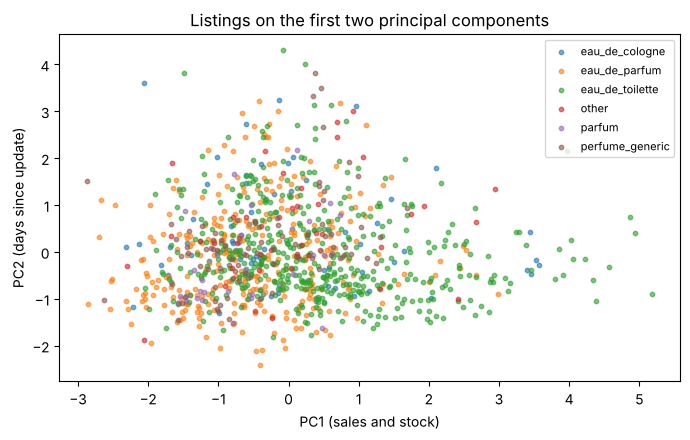

In [20]:
pc = PCA(n_components=2).fit_transform(X)
plt.figure(figsize=(7, 4.5))
for ptype in sorted(df['category_grouped'].unique()):
    m = (df['category_grouped'] == ptype).values
    plt.scatter(pc[m, 0], pc[m, 1], s=10, alpha=0.6, label=ptype)
plt.xlabel('PC1 (sales and stock)'); plt.ylabel('PC2 (days since update)')
plt.title('Listings on the first two principal components'); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 3.5 Clustering methods and the number of clusters (Figures 20 to 22)

     inertia  silhouette  davies_bouldin  calinski_harabasz
k                                                          
2   3687.112       0.206           1.766            267.414
3   3048.925       0.216           1.503            265.876
4   2627.986       0.213           1.462            258.614
5   2253.567       0.214           1.371            267.287
6   2095.208       0.197           1.478            244.786
7   1973.600       0.196           1.533            226.537
8   1879.759       0.179           1.486            210.738
9   1784.770       0.182           1.501            200.606
10  1713.982       0.183           1.452            190.037


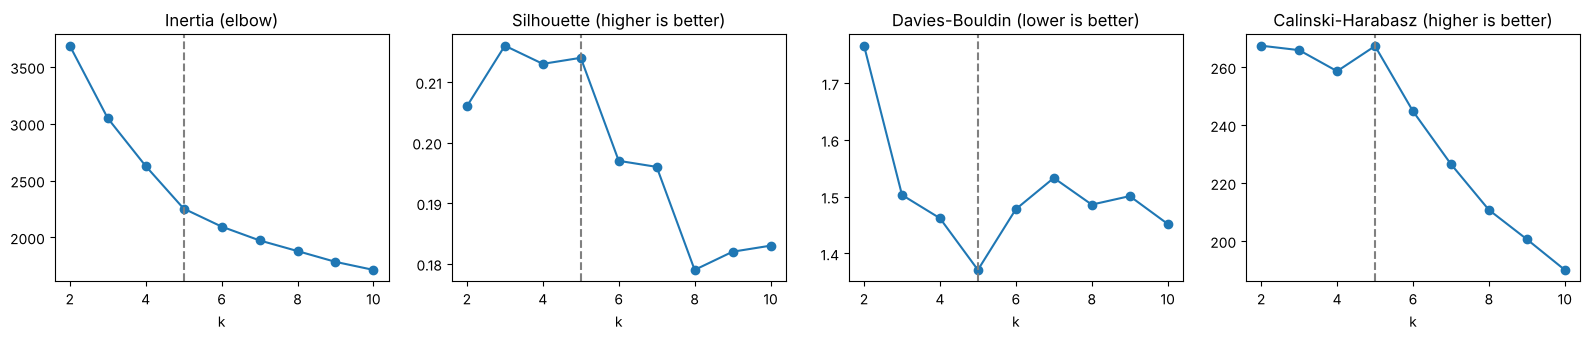

In [21]:
def scores(X, labels):
    return {'silhouette': silhouette_score(X, labels),
            'davies_bouldin': davies_bouldin_score(X, labels),
            'calinski_harabasz': calinski_harabasz_score(X, labels)}

rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
    rows.append({'k': k, 'inertia': km.inertia_, **scores(X, km.labels_)})
k_scores = pd.DataFrame(rows).set_index('k').round(3)
print(k_scores)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
titles = ['Inertia (elbow)', 'Silhouette (higher is better)',
          'Davies-Bouldin (lower is better)', 'Calinski-Harabasz (higher is better)']
for ax, col, title in zip(axes, k_scores.columns, titles):
    ax.plot(k_scores.index, k_scores[col], marker='o'); ax.axvline(5, color='grey', linestyle='--')
    ax.set_title(title); ax.set_xlabel('k')
plt.tight_layout(); plt.show()

7 -> 6 clusters    17.9
6 -> 5 clusters    18.7
5 -> 4 clusters    25.0
4 -> 3 clusters    28.0
3 -> 2 clusters    33.6
2 -> 1 clusters    40.3


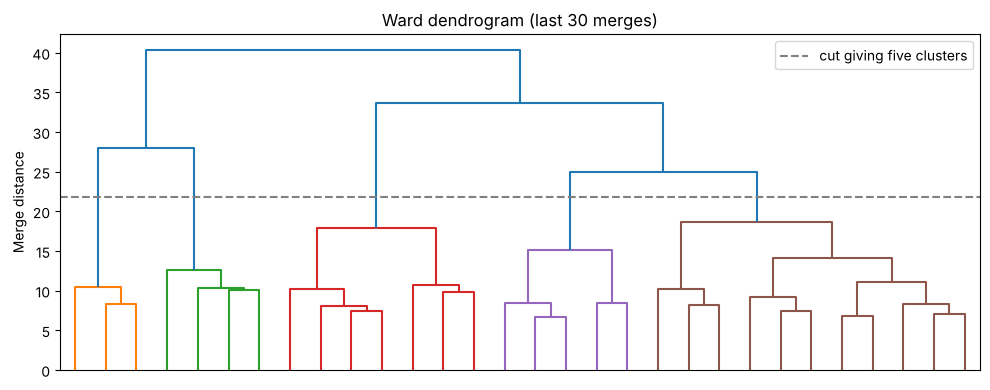

In [22]:
from scipy.cluster.hierarchy import linkage, dendrogram

# Ward linkage joins the two groups whose merger adds the least within-cluster variance,
# the same quantity K-Means minimises, so the two methods are directly comparable
Z = linkage(X, method='ward')
steps = [f'{k + 1} -> {k} clusters' for k in range(6, 0, -1)]
print(pd.Series(Z[-6:, 2].round(1), index=steps, name='merge distance').to_string())
cut = (Z[-5, 2] + Z[-4, 2]) / 2          # a cut between these two merges leaves five clusters

plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode='lastp', p=30, no_labels=True, color_threshold=cut)
plt.axhline(cut, color='grey', linestyle='--', label='cut giving five clusters')
plt.ylabel('Merge distance'); plt.title('Ward dendrogram (last 30 merges)'); plt.legend()
plt.tight_layout(); plt.show()

eps = 0.75: clusters = 5, noise = 45%, clusters holding a single product type = 5
eps = 1.0: clusters = 4, noise = 24%, clusters holding a single product type = 4
eps = 1.25: clusters = 6, noise = 10%, clusters holding a single product type = 6
eps = 1.5: clusters = 1, noise = 3%, clusters holding a single product type = 0


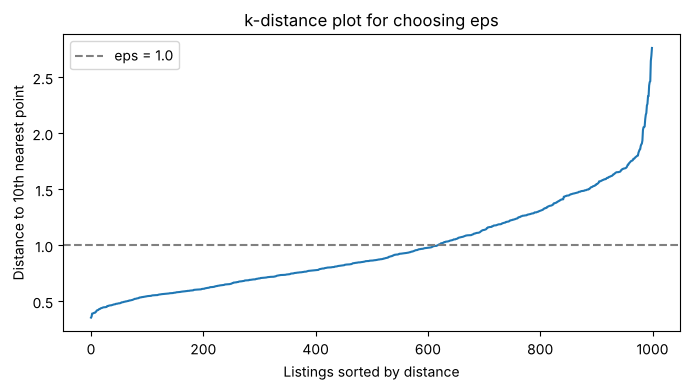

In [23]:
from sklearn.neighbors import NearestNeighbors

# DBSCAN needs eps, the distance within which listings count as neighbours.
# The k-distance plot sorts each listing's distance to its 10th nearest point (min_samples = 10);
# eps is read where the curve bends upwards.
dist = NearestNeighbors(n_neighbors=10).fit(X).kneighbors(X)[0][:, -1]
dist = np.sort(dist)

# What DBSCAN produces at, below and above eps = 1.0
for eps in [0.75, 1.0, 1.25, 1.5]:
    lab = DBSCAN(eps=eps, min_samples=10).fit_predict(X)
    kept = lab != -1
    types = pd.crosstab(lab[kept], df.loc[kept, 'category_grouped']).gt(0).sum(axis=1)
    print(f'eps = {eps}: clusters = {len(set(lab[kept]))}, noise = {(~kept).mean():.0%},',
          f'clusters holding a single product type = {(types == 1).sum()}')

plt.figure(figsize=(7, 4))
plt.plot(dist); plt.axhline(1.0, color='grey', linestyle='--', label='eps = 1.0')
plt.xlabel('Listings sorted by distance'); plt.ylabel('Distance to 10th nearest point')
plt.title('k-distance plot for choosing eps'); plt.legend()
plt.tight_layout(); plt.show()

## 4. Results
### 4.1 Model comparison (Figures 23 and 24)

In [24]:
models = {'K-Means (k = 5)': KMeans(n_clusters=5, n_init=20, random_state=SEED),
          'Hierarchical, Ward (k = 5)': AgglomerativeClustering(n_clusters=5, linkage='ward'),
          'Hierarchical, average (k = 5)': AgglomerativeClustering(n_clusters=5, linkage='average'),
          'DBSCAN (eps = 1.0, min_samples = 10)': DBSCAN(eps=1.0, min_samples=10)}
labels = {name: model.fit_predict(X) for name, model in models.items()}

rows = []
for name, lab in labels.items():
    kept = lab != -1       # DBSCAN marks noise as -1; scores use the clustered listings only
    rows.append({'model': name, 'clusters': len(set(lab[kept])),
                 'noise %': round((~kept).mean() * 100, 1),
                 'largest cluster %': round(np.bincount(lab[kept]).max() / len(lab) * 100, 1),
                 **scores(X[kept], lab[kept])})
print(pd.DataFrame(rows).set_index('model').round(3).to_string())

print('\nDBSCAN clusters by product type (-1 = noise):')
dbscan = labels['DBSCAN (eps = 1.0, min_samples = 10)']
print(pd.crosstab(dbscan, df['category_grouped'], rownames=['DBSCAN cluster']))

                                      clusters  noise %  largest cluster %  silhouette  davies_bouldin  calinski_harabasz
model                                                                                                                    
K-Means (k = 5)                              5      0.0               29.1       0.214           1.371            267.287
Hierarchical, Ward (k = 5)                   5      0.0               37.7       0.149           1.599            199.513
Hierarchical, average (k = 5)                5      0.0               91.2       0.210           0.867             60.146
DBSCAN (eps = 1.0, min_samples = 10)         4     23.7               40.9       0.123           1.677             74.817

DBSCAN clusters by product type (-1 = noise):
category_grouped  eau_de_cologne  eau_de_parfum  eau_de_toilette  other  parfum  perfume_generic
DBSCAN cluster                                                                                  
-1                         

In [25]:
# Does the selected model change with other reasonable choices? Agreement is measured with the
# adjusted Rand index (ARI): 1 = identical segments, 0 = no more agreement than chance
base = labels['K-Means (k = 5)']
X_flags = pd.concat([X, df[['available_limited', 'available_10plus']]], axis=1)   # flags added back
X_pca4 = PCA(n_components=4).fit_transform(X)                                      # 86.7% of variation
for name, data in [('Stock flags added back', X_flags), ('Four principal components', X_pca4)]:
    lab = KMeans(n_clusters=5, n_init=20, random_state=SEED).fit_predict(data)
    print(f'{name}: ARI with the selected model = {adjusted_rand_score(base, lab):.3f}')

runs = [KMeans(n_clusters=5, n_init=20, random_state=s).fit_predict(X) for s in range(10)]
ari = [adjusted_rand_score(runs[i], runs[j]) for i in range(10) for j in range(i + 1, 10)]
print(f'Ten random seeds: mean ARI between runs = {np.mean(ari):.3f} (lowest {np.min(ari):.3f})')

Stock flags added back: ARI with the selected model = 0.972
Four principal components: ARI with the selected model = 0.946


Ten random seeds: mean ARI between runs = 0.991 (lowest 0.979)


### 4.2 The five segments (Figures 25 and 26)

In [26]:
df['cluster'] = labels['K-Means (k = 5)']
df['est_sales_value'] = df['price'] * df['sold']   # estimated cumulative sales value, not revenue
SEGMENTS = ['Bestsellers', 'Bulk stockists', 'Premium slow movers',
            'Stale listings', 'Budget slow movers']

def name_segments(labels, data):
    # K-Means numbers its clusters arbitrarily, so each cluster is named from its medians
    med = data.groupby(labels)[num].median()
    names, remaining = {}, list(med.index)
    for col, name in [('available', 'Bulk stockists'), ('price', 'Premium slow movers'),
                      ('days_since_update', 'Stale listings'), ('sold', 'Bestsellers')]:
        top = med.loc[remaining, col].idxmax(); names[top] = name; remaining.remove(top)
    names[remaining[0]] = 'Budget slow movers'
    return pd.Series(labels, index=data.index).map(names)

df['segment'] = name_segments(df['cluster'], df)
g = df.groupby('segment')
profile = g[num].median().round(2)
profile.insert(0, 'listings', g.size())
profile['limited %'] = (g['available_limited'].mean() * 100).round(0)
profile['value share %'] = (g['est_sales_value'].sum() / df['est_sales_value'].sum() * 100).round(1)
print('Medians unless stated; value share = share of estimated sales value (price x units sold)\n')
print(profile.reindex(SEGMENTS).to_string())

Medians unless stated; value share = share of estimated sales value (price x units sold)

                     listings  price   sold  available  days_since_update  limited %  value share %
segment                                                                                            
Bestsellers               234  35.00  551.0       10.0                1.0       20.0           77.7
Bulk stockists             77  26.86  998.0       86.0                2.0        0.0           14.5
Premium slow movers       254  76.82   21.0        5.0                2.0        3.0            5.2
Stale listings            144  29.99   34.5       10.0               23.0        1.0            1.7
Budget slow movers        291  24.43   19.0        7.0                2.0        1.0            0.9


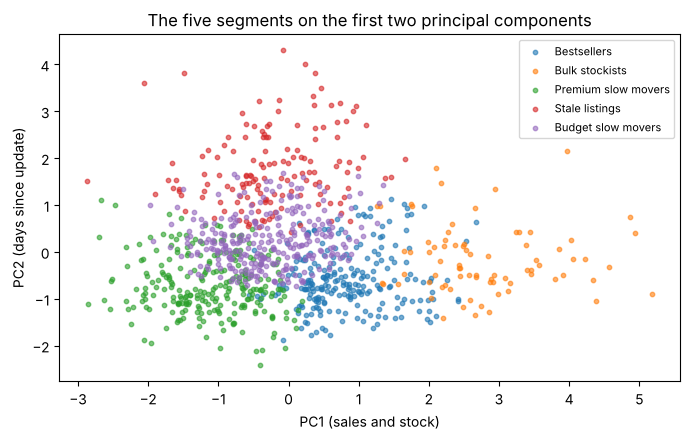

In [27]:
plt.figure(figsize=(7, 4.5))
for seg in SEGMENTS:
    m = (df['segment'] == seg).values
    plt.scatter(pc[m, 0], pc[m, 1], s=10, alpha=0.6, label=seg)
plt.xlabel('PC1 (sales and stock)'); plt.ylabel('PC2 (days since update)')
plt.title('The five segments on the first two principal components'); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 4.3 Four or five clusters? (Figures 27 to 29)

In [28]:
k4 = KMeans(n_clusters=4, n_init=20, random_state=SEED).fit_predict(X)
print(pd.DataFrame({'k = 4': scores(X, k4), 'k = 5': scores(X, df['cluster'])}).round(3))
print('\nWhere the five segments go when k = 4:')
moves = pd.crosstab(df['segment'], k4,
                    rownames=['five-cluster segment'], colnames=['four-cluster group'])
print(moves.reindex(SEGMENTS))

                     k = 4    k = 5
silhouette           0.213    0.214
davies_bouldin       1.462    1.371
calinski_harabasz  258.614  267.287

Where the five segments go when k = 4:
four-cluster group      0    1    2   3
five-cluster segment                   
Bestsellers           229    5    0   0
Bulk stockists          0    0    0  77
Premium slow movers     4  240   10   0
Stale listings          0    0  144   0
Budget slow movers     76  183   29   3


In [29]:
total_value = df['est_sales_value'].sum()

def describe(groups):
    g = df.groupby(groups)
    return pd.DataFrame({'listings': g.size(),
                         'price Q1': g['price'].quantile(.25),
                         'median price': g['price'].median(),
                         'price Q3': g['price'].quantile(.75),
                         'median sold': g['sold'].median(),
                         'value share %': g['est_sales_value'].sum() / total_value * 100}).round(2)
print('Five clusters:'); print(describe(df['segment']).reindex(SEGMENTS).to_string())
print('\nFour clusters (groups 0 to 3):'); print(describe(k4).to_string())

Five clusters:
                     listings  price Q1  median price  price Q3  median sold  value share %
segment                                                                                    
Bestsellers               234     27.60         35.00     50.70        551.0          77.74
Bulk stockists             77     18.10         26.86     35.62        998.0          14.49
Premium slow movers       254     58.99         76.82    100.00         21.0           5.22
Stale listings            144     19.67         29.99     45.17         34.5           1.67
Budget slow movers        291     16.68         24.43     31.99         19.0           0.88

Four clusters (groups 0 to 3):
   listings  price Q1  median price  price Q3  median sold  value share %
0       309     18.91         29.99     45.90        368.0          78.91
1       428     30.86         49.98     79.99         16.0           4.79
2       183     17.24         28.80     45.00         28.0           1.81
3        80  

In [30]:
# Is five clusters consistently better than four? Refit both on 200 bootstrap samples
# (listings drawn at random with replacement) and compare the three indices each time
rng = np.random.default_rng(SEED)
diffs = []
for _ in range(200):
    Xb = X.iloc[rng.integers(0, len(X), len(X))].reset_index(drop=True)
    s4 = scores(Xb, KMeans(n_clusters=4, n_init=20, random_state=SEED).fit_predict(Xb))
    s5 = scores(Xb, KMeans(n_clusters=5, n_init=20, random_state=SEED).fit_predict(Xb))
    diffs.append({m: s5[m] - s4[m] for m in s4})
diffs = pd.DataFrame(diffs)
five_better = pd.Series({'silhouette': (diffs['silhouette'] > 0).mean(),
                         'davies_bouldin': (diffs['davies_bouldin'] < 0).mean(),   # lower is better
                         'calinski_harabasz': (diffs['calinski_harabasz'] > 0).mean()})
print(pd.DataFrame({'mean difference (5 - 4)': diffs.mean(), '2.5%': diffs.quantile(.025),
                    '97.5%': diffs.quantile(.975), 'samples where 5 is better': five_better}).round(3))

                   mean difference (5 - 4)   2.5%   97.5%  samples where 5 is better
silhouette                           0.009 -0.010   0.022                      0.810
davies_bouldin                      -0.099 -0.154  -0.025                      1.000
calinski_harabasz                    4.409 -7.887  14.732                      0.775


### 4.4 Sensitivity to stock assumptions (Figure 30)

In [31]:
censored = df['available_10plus'] == 1      # stored as 10, but only known to be 'more than 10'
# scenario: (value for the 297 censored listings, value for the 64 imputed listings)
scenarios = {'Baseline': (10, 9), 'S1: censored = 15': (15, 9), 'S2: missing = 4': (10, 4),
             'S3: both (15 and 4)': (15, 4), 'S4: censored = 50': (50, 9)}

rows = []
for name, (censored_value, missing_value) in scenarios.items():
    d = df.copy()
    d.loc[censored, 'available'] = censored_value
    d.loc[stock_imputed, 'available'] = missing_value
    scaled_s = pd.DataFrame(StandardScaler().fit_transform(np.log1p(d[num])), columns=num)
    Xs = pd.concat([scaled_s, cat_dummies], axis=1)      # same steps as Section 3.3
    lab = KMeans(n_clusters=5, n_init=20, random_state=SEED).fit_predict(Xs)
    seg = name_segments(lab, d)                          # same naming rule as Section 4.2
    rows.append({'scenario': name, 'same segment %': round((seg == df['segment']).mean() * 100, 1),
                 'ARI': round(adjusted_rand_score(df['cluster'], lab), 3),
                 'silhouette': round(silhouette_score(Xs, lab), 3),
                 **seg.value_counts().reindex(SEGMENTS, fill_value=0).to_dict()})
print(pd.DataFrame(rows).set_index('scenario').to_string())

print('\nWhere listings move under S4 (rows = baseline segment):')
moves = pd.crosstab(df['segment'], seg, colnames=['segment under S4'])
print(moves.reindex(index=SEGMENTS, columns=SEGMENTS, fill_value=0))

moved_in = (seg == 'Bulk stockists') & (df['segment'] != 'Bulk stockists')
print(f'\nListings moving into Bulk stockists under S4: {moved_in.sum()}',
      f'| share that are censored: {censored[moved_in].mean():.0%}')

                     same segment %    ARI  silhouette  Bestsellers  Bulk stockists  Premium slow movers  Stale listings  Budget slow movers
scenario                                                                                                                                    
Baseline                      100.0  1.000       0.214          234              77                  254             144                 291
S1: censored = 15              98.1  0.955       0.205          234              72                  248             147                 299
S2: missing = 4                97.8  0.938       0.216          230              78                  248             144                 300
S3: both (15 and 4)            98.5  0.962       0.206          232              74                  252             145                 297
S4: censored = 50              74.7  0.518       0.192          148             231                  213             134                 274

Where listin

# Task 2: Figures 31 and 32

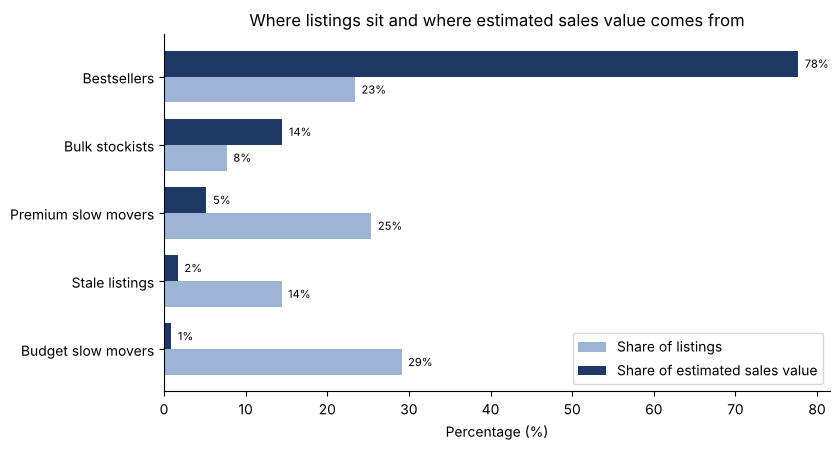

In [32]:
prof = profile.sort_values('value share %', ascending=False)
listing_share = prof['listings'] / prof['listings'].sum() * 100
fig, ax = plt.subplots(figsize=(8.5, 4.6))
y, h = np.arange(len(prof)), 0.38
ax.barh(y + h / 2, listing_share, h, label='Share of listings', color='#9DB4D4')
ax.barh(y - h / 2, prof['value share %'], h, label='Share of estimated sales value', color='#1F3864')
for yy, a, b in zip(y, listing_share, prof['value share %']):
    ax.text(a + 0.8, yy + h / 2, f'{a:.0f}%', va='center', fontsize=8)
    ax.text(b + 0.8, yy - h / 2, f'{b:.0f}%', va='center', fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(prof.index); ax.invert_yaxis()
ax.set_xlabel('Percentage (%)'); ax.set_title('Where listings sit and where estimated sales value comes from')
ax.legend(loc='lower right'); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('fig_task2_value.png', dpi=150); plt.show()

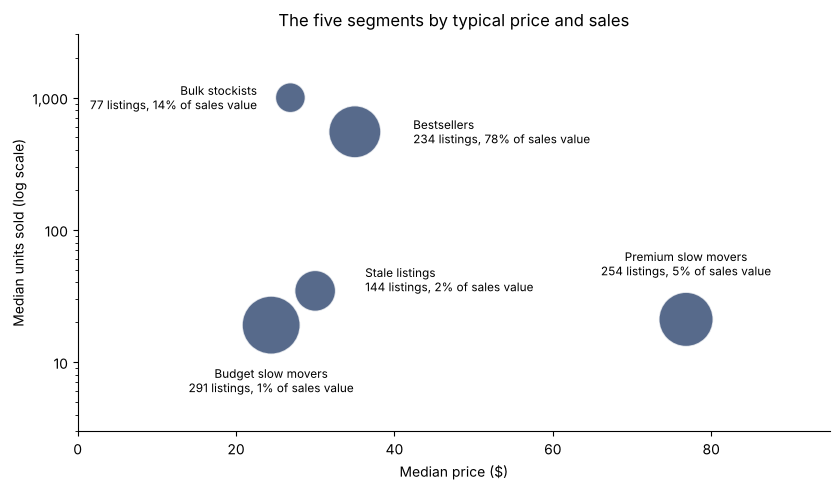

In [33]:
offsets = {'Bestsellers': (42, 0, 'left'), 'Bulk stockists': (-24, 0, 'right'), 'Stale listings': (36, 8, 'left'),
           'Budget slow movers': (0, -40, 'center'), 'Premium slow movers': (0, 40, 'center')}
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(profile['price'], profile['sold'], s=profile['listings'] * 6, color='#1F3864', alpha=0.75, edgecolor='white')
for seg, r in profile.iterrows():
    dx, dy, ha = offsets[seg]
    ax.annotate(f"{seg}\n{int(r['listings'])} listings, {r['value share %']:.0f}% of sales value", (r['price'], r['sold']),
                textcoords='offset points', xytext=(dx, dy), ha=ha, va='center', fontsize=8.5)
ax.set_yscale('log'); ax.set_ylim(3, 3000); ax.set_xlim(0, 95)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_xlabel('Median price ($)'); ax.set_ylabel('Median units sold (log scale)')
ax.set_title('The five segments by typical price and sales'); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('fig_task2_segments.png', dpi=150); plt.show()